# Практика 2. Проверка статистических гипотез
Данные INSEE: доход и бедность по департаментам Франции, 2023 год.
Источник: https://www.insee.fr/fr/statistiques/8984748, таблицы Figure 1a и Figure 2a.

In [1]:
# Библиотеки
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy import stats

scipy_version = scipy.__version__.split(".")
if int(scipy_version[0]) == 1 and int(scipy_version[1]) < 16:
    raise ImportError('Для ANOVA Уэлча нужна SciPy >= 1.16. Обновите scipy командой выше.')
print("Версия SciPy:", scipy.__version__)


Версия SciPy: 1.18.0


In [2]:
# Исходные данные. Доход - медиана располагаемого дохода, €/год на единицу потребления.
# Бедность - доля жителей ниже 60% медианного уровня жизни метрополии, %.
raw_csv = """code,department,income_eur,poverty_pct
01,Ain,27990,12.2
02,Aisne,23360,19.4
03,Allier,24430,16.4
04,Alpes-de-Haute-Provence,24240,18.6
05,Hautes-Alpes,25060,14.3
06,Alpes-Maritimes,26380,17.7
07,Ardèche,24820,15.6
08,Ardennes,23500,19.9
09,Ariège,23360,20.0
10,Aube,24130,18.1
11,Aude,23060,21.2
12,Aveyron,24780,14.5
13,Bouches-du-Rhône,25610,20.3
14,Calvados,25600,13.5
15,Cantal,24820,13.7
16,Charente,24850,15.4
17,Charente-Maritime,25710,13.1
18,Cher,24730,15.9
19,Corrèze,24910,14.4
21,Côte-d'Or,26560,13.0
22,Côtes-d'Armor,25590,12.2
23,Creuse,23210,19.5
24,Dordogne,24150,17.1
25,Doubs,27190,13.4
26,Drôme,25210,16.0
27,Eure,25520,13.8
28,Eure-et-Loir,25980,13.3
29,Finistère,26210,11.4
2A,Corse-du-Sud,26050,17.9
2B,Haute-Corse,24200,21.8
30,Gard,23930,21.0
31,Haute-Garonne,27040,15.9
32,Gers,24770,15.6
33,Gironde,26820,14.2
34,Hérault,24280,21.0
35,Ille-et-Vilaine,26670,11.7
36,Indre,24020,15.8
37,Indre-et-Loire,25930,14.1
38,Isère,27290,13.0
39,Jura,26090,12.3
40,Landes,25650,12.1
41,Loir-et-Cher,25240,14.0
42,Loire,24800,16.8
43,Haute-Loire,25140,12.4
44,Loire-Atlantique,27150,11.5
45,Loiret,25800,15.0
46,Lot,24740,15.8
47,Lot-et-Garonne,23730,18.5
48,Lozère,24270,15.3
49,Maine-et-Loire,25550,11.8
50,Manche,25430,12.0
51,Marne,25700,15.8
52,Haute-Marne,23980,16.0
53,Mayenne,25140,11.6
54,Meurthe-et-Moselle,25910,16.1
55,Meuse,24740,15.0
56,Morbihan,26250,11.3
57,Moselle,26030,16.6
58,Nièvre,24010,17.3
59,Nord,23810,20.7
60,Oise,25970,14.5
61,Orne,24110,16.3
62,Pas-de-Calais,23260,19.1
63,Puy-de-Dôme,26040,14.8
64,Pyrénées-Atlantiques,26300,13.3
65,Hautes-Pyrénées,24320,16.6
66,Pyrénées-Orientales,23080,22.4
67,Bas-Rhin,26890,15.0
68,Haut-Rhin,27620,14.1
69,Rhône,27500,16.3
70,Haute-Saône,24750,13.8
71,Saône-et-Loire,24970,14.1
72,Sarthe,24990,14.1
73,Savoie,27910,11.1
74,Haute-Savoie,32180,10.2
75,Paris,33650,16.8
76,Seine-Maritime,24940,16.6
77,Seine-et-Marne,27480,13.6
78,Yvelines,31520,11.6
79,Deux-Sèvres,25080,12.7
80,Somme,24200,17.3
81,Tarn,24420,16.4
82,Tarn-et-Garonne,24350,17.0
83,Var,25940,16.8
84,Vaucluse,23840,21.4
85,Vendée,25850,9.2
86,Vienne,24940,15.5
87,Haute-Vienne,24740,17.1
88,Vosges,24320,15.8
89,Yonne,24590,16.0
90,Territoire de Belfort,25910,17.1
91,Essonne,27940,15.4
92,Hauts-de-Seine,33790,13.5
93,Seine-Saint-Denis,21250,29.5
94,Val-de-Marne,27250,18.4
95,Val-d'Oise,25890,19.4
974,La Réunion,19110,36.4
"""
source_data = pd.read_csv(io.StringIO(raw_csv), dtype={"code": str})
data = source_data[source_data["code"] != "974"].copy()
assert len(source_data) == 97 and len(data) == 96
assert data["code"].is_unique
assert not data.isna().any().any()

print("Первые строки:")
print(data.head(3).to_string(index=False))
print("Последние строки:")
print(data.tail(3).to_string(index=False))


Первые строки:
code department  income_eur  poverty_pct
  01        Ain       27990         12.2
  02      Aisne       23360         19.4
  03     Allier       24430         16.4
Последние строки:
code        department  income_eur  poverty_pct
  93 Seine-Saint-Denis       21250         29.5
  94      Val-de-Marne       27250         18.4
  95        Val-d'Oise       25890         19.4


In [3]:
# Группы заданы по географии регионов, а не по величине дохода.
# Север: Bretagne, Normandie, Pays de la Loire, Hauts-de-France, Grand Est,
# Bourgogne-Franche-Comté, Centre-Val de Loire.
# Юг: Nouvelle-Aquitaine, Occitanie, Auvergne-Rhône-Alpes,
# Provence-Alpes-Côte d'Azur, Corse. Île-de-France выделен отдельно.
# Это авторские группы, а не официальная классификация INSEE.
# Состав регионов: https://www.insee.fr/fr/information/8740222
north_codes = [
    "02", "08", "10", "14", "18", "21", "22", "25", "27", "28", "29", "35",
    "36", "37", "39", "41", "44", "45", "49", "50", "51", "52", "53", "54",
    "55", "56", "57", "58", "59", "60", "61", "62", "67", "68", "70", "71",
    "72", "76", "80", "85", "88", "89", "90"
]
idf_codes = ["75", "77", "78", "91", "92", "93", "94", "95"]

data["group"] = "Юг"
data.loc[data["code"].isin(north_codes), "group"] = "Север"
data.loc[data["code"].isin(idf_codes), "group"] = "Île-de-France"

north_income = data.loc[data["group"] == "Север", "income_eur"].to_numpy()
south_income = data.loc[data["group"] == "Юг", "income_eur"].to_numpy()
idf_income = data.loc[data["group"] == "Île-de-France", "income_eur"].to_numpy()
assert len(north_income) == 43 and len(south_income) == 45 and len(idf_income) == 8
print(data["group"].value_counts().to_string())


group
Юг               45
Север            43
Île-de-France     8


In [4]:
# Описательные статистики
summary = data.groupby("group")["income_eur"].agg(["count", "mean", "std", "median", "min", "max"])
summary = summary.reindex(["Север", "Юг", "Île-de-France"])
print(summary.round(2).to_string())
print("Среднее департаментских медиан не равно среднему доходу жителей Франции.")


               count      mean      std   median    min    max
group                                                         
Север             43  25306.74  1085.80  25520.0  23260  27620
Юг                45  25243.11  1621.33  24820.0  23060  32180
Île-de-France      8  28596.25  4240.01  27710.0  21250  33790
Среднее департаментских медиан не равно среднему доходу жителей Франции.


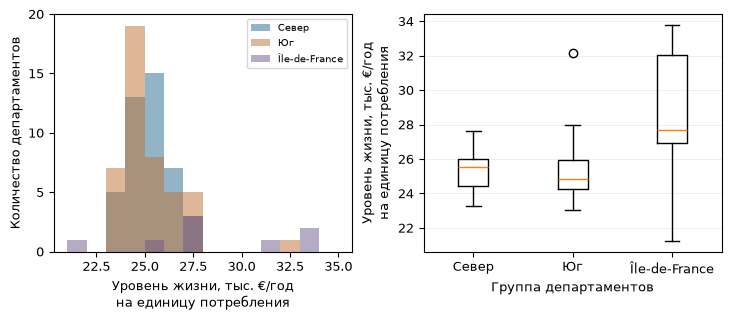

In [5]:
# Распределение доходов по группам
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 9})
fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.1), layout="constrained")
bins = np.arange(21, 36, 1)
axes[0].hist(north_income / 1000, bins=bins, alpha=0.5, label="Север", color="#28688f")
axes[0].hist(south_income / 1000, bins=bins, alpha=0.5, label="Юг", color="#be7035")
axes[0].hist(idf_income / 1000, bins=bins, alpha=0.5, label="Île-de-France", color="#6f588a")
axes[0].set_xlabel("Уровень жизни, тыс. €/год\nна единицу потребления")
axes[0].set_ylabel("Количество департаментов")
axes[0].set_yticks([0, 5, 10, 15, 20])
axes[0].legend(fontsize=7)
axes[1].boxplot([north_income / 1000, south_income / 1000, idf_income / 1000],
                tick_labels=["Север", "Юг", "Île-de-France"])
axes[1].set_ylabel("Уровень жизни, тыс. €/год\nна единицу потребления")
axes[1].set_xlabel("Группа департаментов")
axes[1].grid(axis="y", alpha=0.2)
plt.show()


In [6]:
# Z-критерий двух долей: сравниваем Север и Юг.
# H0: доли департаментов с доходом не ниже 25 840 € равны. H1: доли различаются.
# 25 840 € - опубликованный INSEE общий ориентир, не оценка по этим 96 строкам.
# Это Z-критерий долей, поэтому известная генеральная дисперсия не нужна.
alpha = 0.05
income_reference = 25840
poverty_reference = 16.2
north_size = len(north_income)
south_size = len(south_income)
north_high = (north_income >= income_reference).sum()
south_high = (south_income >= income_reference).sum()
north_share = north_high / north_size
south_share = south_high / south_size
pooled_share = (north_high + south_high) / (north_size + south_size)
z_error = np.sqrt(pooled_share * (1 - pooled_share) * (1 / north_size + 1 / south_size))
z_stat = (north_share - south_share) / z_error
z_p = 2 * stats.norm.sf(abs(z_stat))  # Два хвоста стандартной нормали.
z_critical = stats.norm.ppf(1 - alpha / 2)

print(f"Доли: {north_high}/{north_size} = {north_share:.4f}; {south_high}/{south_size} = {south_share:.4f}")
print("При H0 ожидаются успехи и неуспехи:")
print(north_size * pooled_share, north_size * (1 - pooled_share))
print(south_size * pooled_share, south_size * (1 - pooled_share))
print(f"Z = {z_stat:.6f}; p = {z_p:.6f}; H0 отклоняется при |Z| > {z_critical:.4f}")


Доли: 16/43 = 0.3721; 12/45 = 0.2667
При H0 ожидаются успехи и неуспехи:
13.681818181818182 29.31818181818182
14.318181818181818 30.681818181818183
Z = 1.061393; p = 0.288511; H0 отклоняется при |Z| > 1.9600


In [7]:
# t-критерий Уэлча: сравниваем средние доходы Севера и Юга.
# H0: средние равны. H1: средние различаются.
# equal_var=False разрешает разные дисперсии, two-sided задаёт два хвоста.
t_result = stats.ttest_ind(north_income, south_income, equal_var=False,
                           alternative="two-sided", nan_policy="raise")
t_critical = stats.t.ppf(1 - alpha / 2, t_result.df)
mean_difference = north_income.mean() - south_income.mean()
t_interval = t_result.confidence_interval(confidence_level=0.95)

print(f"t = {t_result.statistic:.6f}; df = {t_result.df:.4f}; p = {t_result.pvalue:.6f}")
print(f"H0 отклоняется при |t| > {t_critical:.4f}")
print(f"Разность средних: {mean_difference:.2f} €")
print(f"Модельный 95% интервал: [{t_interval.low:.2f}; {t_interval.high:.2f}] €")


t = 0.217197; df = 77.1834; p = 0.828628
H0 отклоняется при |t| > 1.9912
Разность средних: 63.63 €
Модельный 95% интервал: [-519.73; 647.00] €


In [8]:
# χ² Пирсона: связь двух бинарных признаков на всех 96 департаментах.
# H0: доход >= 25 840 € и бедность > 16,2% независимы. H1: признаки связаны.
# Порог 16,2% тоже взят из публикации INSEE как общий ориентир.
table = pd.crosstab(data["income_eur"] >= income_reference,
                    data["poverty_pct"] > poverty_reference)
table = table.reindex(index=[True, False], columns=[True, False])
table.index = ["Доход >= 25 840", "Доход < 25 840"]
table.columns = ["Бедность > 16,2%", "Бедность <= 16,2%"]
chi_stat, chi_p, chi_df, expected = stats.chi2_contingency(table, correction=False)
# correction=False — исходный критерий Пирсона без поправки Йейтса.
chi_critical = stats.chi2.ppf(1 - alpha, chi_df)
cramers_v = np.sqrt(chi_stat / len(data))

print("Наблюдаемые частоты:")
print(table.to_string())
print("Ожидаемые частоты:")
print(pd.DataFrame(expected, index=table.index, columns=table.columns).round(2).to_string())
print(f"Минимальная ожидаемая частота: {expected.min():.2f} (должна быть >= 5)")
print(f"χ² = {chi_stat:.6f}; df = {chi_df}; p = {chi_p:.6f}; V Крамера = {cramers_v:.4f}")
print(f"H0 отклоняется при χ² > {chi_critical:.4f}")


Наблюдаемые частоты:
                 Бедность > 16,2%  Бедность <= 16,2%
Доход >= 25 840                 9                 26
Доход < 25 840                 28                 33
Ожидаемые частоты:
                 Бедность > 16,2%  Бедность <= 16,2%
Доход >= 25 840             13.49              21.51
Доход < 25 840              23.51              37.49
Минимальная ожидаемая частота: 13.49 (должна быть >= 5)
χ² = 3.826257; df = 1; p = 0.050455; V Крамера = 0.1996
H0 отклоняется при χ² > 3.8415


In [9]:
# F-критерий: однофакторный анализ средних трёх групп, вариант Уэлча.
# H0: все три средних равны. H1: хотя бы одно среднее отличается.
# equal_var=False разрешает разные дисперсии. F и p считает библиотека.
# Это F-проверка средних, а не классическое отношение двух дисперсий.
f_result = stats.f_oneway(north_income, south_income, idf_income,
                          equal_var=False, nan_policy="raise")

# SciPy не возвращает df для этой команды, поэтому отдельно найдём только df.
sizes = np.array([len(north_income), len(south_income), len(idf_income)])
variances = np.array([north_income.var(ddof=1), south_income.var(ddof=1), idf_income.var(ddof=1)])
weights = sizes / variances
df_sum = ((1 - weights / weights.sum()) ** 2 / (sizes - 1)).sum()
f_df1 = 2  # Три группы: k - 1 = 2.
f_df2 = (3 ** 2 - 1) / (3 * df_sum)
f_critical = stats.f.ppf(1 - alpha, f_df1, f_df2)

print(f"F = {f_result.statistic:.6f}; df = ({f_df1}; {f_df2:.4f}); p = {f_result.pvalue:.6f}")
print(f"H0 отклоняется при F > {f_critical:.4f}")


F = 2.350686; df = (2; 17.3569); p = 0.124905
H0 отклоняется при F > 3.5778


In [10]:
# Проверка условий применения критериев
print("Нормальность доходов: Shapiro-Wilk, H0 - нормальное распределение.")
for group_name, income in [("Север", north_income), ("Юг", south_income), ("Île-de-France", idf_income)]:
    normality = stats.shapiro(income)
    print(f"{group_name}: W = {normality.statistic:.4f}; p = {normality.pvalue:.3g}")

# Вариант Левена с центром в медиане называется критерием Brown-Forsythe.
variance_test = stats.levene(north_income, south_income, idf_income, center="median")
print(f"Brown-Forsythe: W = {variance_test.statistic:.4f}; p = {variance_test.pvalue:.3g}")
print("Разные дисперсии обосновывают использование Уэлча.")
print("У Юга есть асимметрия: t и F применены как приближения для средних.")
print("В IDF всего 8 департаментов: неотвержение нормальности не доказывает её.")


Нормальность доходов: Shapiro-Wilk, H0 - нормальное распределение.
Север: W = 0.9782; p = 0.578
Юг: W = 0.8465; p = 2.98e-05
Île-de-France: W = 0.9296; p = 0.512
Brown-Forsythe: W = 11.1814; p = 4.45e-05
Разные дисперсии обосновывают использование Уэлча.
У Юга есть асимметрия: t и F применены как приближения для средних.
В IDF всего 8 департаментов: неотвержение нормальности не доказывает её.


In [11]:
# Дополнительные проверки на тех же данных
# Mann-Whitney: H0 - распределения дохода Севера и Юга одинаковы.
# При разных формах распределений это не тест только медиан.
rank_test = stats.mannwhitneyu(north_income, south_income, alternative="two-sided",
                              method="asymptotic", use_continuity=True)
# method учитывает совпадающие ранги; use_continuity - поправка непрерывности.
print(f"Mann-Whitney: U = {rank_test.statistic:.1f}; p = {rank_test.pvalue:.6f}")

# Spearman: H0 - ранговая корреляция дохода и бедности равна нулю.
correlation = stats.spearmanr(data["income_eur"], data["poverty_pct"], alternative="two-sided")
print(f"Spearman: r = {correlation.statistic:.6f}; приближённое p = {correlation.pvalue:.3g}")
print("При n=96 очень малое p Spearman нельзя считать точным: используется приближение.")


Mann-Whitney: U = 1068.5; p = 0.401491
Spearman: r = -0.627775; приближённое p = 7.63e-12
При n=96 очень малое p Spearman нельзя считать точным: используется приближение.


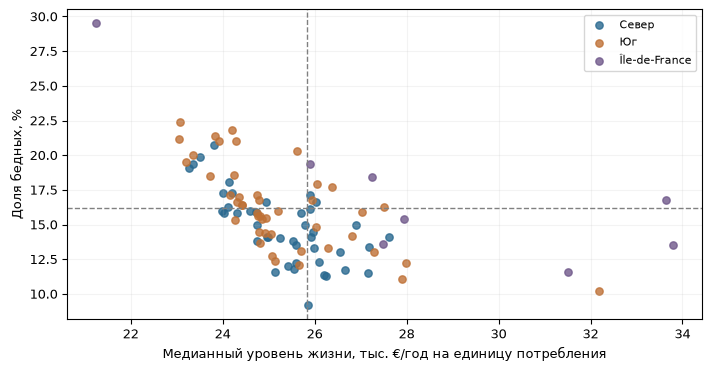

In [12]:
# Доход и бедность на непрерывных шкалах
fig, ax = plt.subplots(figsize=(7, 3.6), layout="constrained")
for group_name, color in [("Север", "#28688f"), ("Юг", "#be7035"), ("Île-de-France", "#6f588a")]:
    group_data = data[data["group"] == group_name]
    ax.scatter(group_data["income_eur"] / 1000, group_data["poverty_pct"],
               label=group_name, color=color, alpha=0.8, s=28)
ax.axvline(income_reference / 1000, color="gray", linestyle="--", linewidth=1)
ax.axhline(poverty_reference, color="gray", linestyle="--", linewidth=1)
ax.set_xlabel("Медианный уровень жизни, тыс. €/год на единицу потребления")
ax.set_ylabel("Доля бедных, %")
ax.legend(fontsize=8)
ax.grid(alpha=0.15)
plt.show()


## Выводы
При α=0,05 все четыре основные гипотезы не отвергаются:
Z: p=0,288511; t: p=0,828628; χ²: p=0,050455; F: p=0,124905.
Для Z и t критическая область двусторонняя; для χ² и F - верхний хвост.
Поправка на множественные проверки не применялась. Все основные p уже > 0,05.
Разность средних Севера и Юга составляет 63,63 €, а модельный 95% интервал
[−519,73; 647,00] € содержит ноль. Это не доказывает равенство средних.
Mann-Whitney (p=0,401491) также не выявляет различия распределений Севера и Юга.
У Île-de-France высокий средний доход, но большой разброс и небольшой объём группы.
F-проверка поэтому не даёт достаточных оснований говорить о различии трёх средних.
На графике распределений виден правый хвост Юга и большой разброс Île-de-France.
Доход и бедность на непрерывных шкалах связаны отрицательно: r Spearman=−0,6278.
При сведении показателей к двум категориям часть информации теряется; χ² даёт
пограничное p=0,050455, которое нельзя округлять до 0,05 ради смены решения.
Выводы относятся к агрегатам территорий, а не к отдельным людям или причинности.
Независимость департаментов условна: пространственная связь ограничивает интерпретацию p.
Документация: https://docs.scipy.org/doc/scipy/reference/stats.html
Z двух долей: https://www.itl.nist.gov/div898/handbook/prc/section3/prc33.htm
